# Introduction to Python

## Python as a tool for physics

In this course, you will develop your Python skills while using calculations and plots to investigate physical models. Begin with a question and an expected trend, translate the relevant equations into code, and explain what the output tells you. You should be able to describe the purpose of every calculation you submit.

Python is a general-purpose programming language. Its scientific packages provide tools for numerical calculations and visualization, while Jupyter notebooks keep code beside your written reasoning. **NumPy** supplies arrays and mathematical functions; **Matplotlib** produces figures. This introduction uses Python 3 throughout.

Work through the examples in order, predict their outputs, and then change one input at a time. Return to individual sections as new assignments require them. The [Markdown introduction](https://saturnaxis.github.io/ModernPhysics/Preamble/Markdown-basics.html) explains mathematical writing, and the [homework template](https://saturnaxis.github.io/ModernPhysics/Preamble/HW_template.html) gives the submission requirements.

## Running a notebook in Google Colab

Use the rocket ship launch menu on a course chapter to open its notebook in Google Colab, then save your own copy to Google Drive. Execute a code cell with its run button or Shift+Enter. A text cell contains your explanation; a code cell contains Python that the runtime executes.

**Include the necessary import statements at the beginning of every code cell that uses a package**, even if an earlier cell imports the same package. For example, repeat `import numpy as np` in each cell that uses `np`, and include `import matplotlib.pyplot as plt` in each plotting cell. This avoids hunting for an import cell after reconnecting to a new Colab runtime. Repeating an import is safe; cells that use only built-in Python need no imports.

Imports restore access to packages, but they do not recreate your own variables or functions. Rerun any cells that define inputs or functions needed by the current cell.

A notebook remembers variables from executed cells, even if you later edit their source. Run cells from top to bottom. After changing an input, rerun the calculations that depend on it. Before submission, restart the runtime and run the notebook from the beginning to check that it works without old variables left in memory.

```{note}
Saving the notebook and keeping a running Python session are different things. Use **Ctrl+S frequently** (Command+S on a Mac) and confirm that saving has finished. A runtime reset removes variables from memory; rerun the cells to recreate them. Files generated only in the runtime must be saved or downloaded separately if you need to retain them.
```

The executable examples below do not require interactive input. They can be run from beginning to end; descriptions of deliberate mistakes appear as text rather than cells that interrupt the notebook.

## Arithmetic and variables

A variable name refers to a value. Use `=` to assign a value, then use the name in an expression. Python distinguishes uppercase and lowercase names, so `energy` and `Energy` are different. Choose descriptive names and avoid replacing built-in names such as `list`, `sum`, or `input`.

In [1]:
x = 4  # First dimensionless example value.
y = 16  # Second dimensionless example value.
print(x * y)
print(x**2)
print(y / x)

64
16
4.0


In Python 3, `/` performs true division: dividing integers can produce a fractional result. `//` performs floor division, which rounds down toward negative infinity, while `%` gives the remainder. Use `**` for powers; `^` is a bitwise operator and does not mean exponentiation.

| Operation | Python example | Meaning |
| --- | --- | --- |
| Addition and subtraction | `x + y`, `x - y` | Sum and difference |
| Multiplication | `x * y` | Explicit multiplication |
| Division | `x / y` | True division |
| Floor division | `x // y` | Quotient rounded down |
| Remainder | `x % y` | Remainder after division |
| Power | `x**2` | Square of `x` |

Use parentheses to make grouping clear. `1 / (2 * x)` differs from `1 / 2 * x`, and `-2**2` differs from `(-2)**2`.

In [2]:
print(2 / 4)
print(10 // 4)
print(-10 // 4)
print(10 % 3)
print(8**(1 / 3))
print(int(2 / 4))

0.5
2
-3
1
2.0
0


The cube-root expression uses `1 / 3` directly; Python 3 does not turn that fraction into zero. `int()` converts a number to an integer by truncating toward zero, which explains the last output. Conversion is different from rounding.

Scientific notation in code uses `e`, as in `6.62607015e-34`. This notation is part of the numeric literal; it is not a multiplication by a variable named `e`.

## Comments, constants, and units

Comments begin with `#` and continue to the end of the line. Use them to identify physical meaning, units, and assumptions. Write for **future-you**, who may no longer remember why a particular expression was chosen.

Several comment lines can each begin with `#`. Triple-quoted text is a string, not a special block-comment syntax; inside a function it is commonly used as a documentation string, or *docstring*.

Ordinary Python numbers do not carry physical units. Choose a consistent unit system, document it, and convert explicitly. You can retrieve constants from SciPy or assign them explicitly, as shown below. Both approaches require you to track units.

### Using `scipy.constants`

Use `from scipy import constants as const` in each cell that accesses `const`. This avoids retyping familiar constants. Common attributes are listed below; the returned numbers do not carry unit labels or perform unit conversions automatically.

| Python name | Quantity | SI unit |
| --- | --- | --- |
| `const.c` | Speed of light | m/s |
| `const.h` | Planck constant | J s |
| `const.hbar` | Reduced Planck constant | J s |
| `const.m_e` | Electron mass | kg |
| `const.k` | Boltzmann constant | J/K |
| `const.e` | Elementary charge | C |
| `const.electron_volt` | Energy of one electronvolt | J |

For example, convert nanometers to meters, evaluate $E=hc/\lambda$ in joules, and divide by `const.electron_volt` to express the energy in eV. `const.e` and `const.electron_volt` have the same numerical value in SI but represent different quantities; the latter makes an energy conversion clearer.


In [3]:
from scipy import constants as const

wavelength_example_nm = 500.0  # Wavelength, nm; four significant figures.
wavelength_example_m = wavelength_example_nm * 1e-9  # Wavelength, m.
energy_example_j = const.h * const.c / wavelength_example_m  # Photon energy, J.
energy_example_ev = energy_example_j / const.electron_volt  # Photon energy, eV.
print(f"Photon energy = {energy_example_j:.3e} J = {energy_example_ev:.3f} eV")


Photon energy = 3.973e-19 J = 2.480 eV


For less familiar constants, `const.find("Bohr radius")` returns matching database names. A lookup in `const.physical_constants` returns **value, unit, and absolute uncertainty**. Read the unit: some database entries use eV or other units instead of SI. Keep the retrieved precision during calculations and format the final answer to match the problem. An exact constant does not remove uncertainty in measured inputs.


In [4]:
from scipy import constants as const

print(const.find("Bohr radius"))
bohr_radius, radius_unit, radius_uncertainty = const.physical_constants["Bohr radius"]
print(f"Bohr radius (rounded for display) = {bohr_radius:.3e} {radius_unit}")
print(f"Tabulated absolute uncertainty = {radius_uncertainty:.2g} {radius_unit}")


['Bohr radius']
Bohr radius (rounded for display) = 5.292e-11 m
Tabulated absolute uncertainty = 8.2e-21 m


Consult the [SciPy constants reference](https://docs.scipy.org/doc/scipy/reference/constants.html) for names and units. The same familiar constants can also be assigned explicitly, as in the following example; subsequent cells use these short variable names.


In [5]:
h = 6.62607015e-34  # Planck constant, J s.
c = 299792458.0  # Speed of light in vacuum, m/s.
e_charge = 1.602176634e-19  # Elementary charge, C; also joules per electronvolt.
frequency = 5.00e14  # Photon frequency, Hz.
energy = h * frequency  # Photon energy, J.
print(f"Photon energy = {energy:.2e} J")

Photon energy = 3.31e-19 J


The calculation implements $E=h\nu$. Explain that relationship in a text cell and interpret the result there. The numerical output by itself does not tell a reader what was calculated or whether it is sensible.

## Input, output, and readable numbers

Use `print()` to display a value and `type()` to inspect its type. An *f-string* puts expressions inside braces and can control how numbers are displayed.

In [6]:
print(type(frequency))
print(f"Photon energy = {energy:.2e} J")
print(f"Photon energy = {energy / e_charge:.3g} eV")

<class 'float'>
Photon energy = 3.31e-19 J
Photon energy = 2.07 eV


The format `.2e` gives scientific notation with two digits after the decimal point, or three significant figures in total. `.3g` gives three significant figures and selects fixed or scientific notation. A format changes the displayed text, not the stored number.

| Format inside an f-string | Use |
| --- | --- |
| `{value:.3f}` | Three digits after the decimal point |
| `{value:.2e}` | Scientific notation with three significant figures |
| `{value:.3g}` | Three significant figures |
| `{count:d}` | An integer |

```{note}
**Printed digits are not justified significant figures.** Python may display many digits, but the meaningful precision of a physical result is limited by the input data, uncertainties, model, and numerical method. Formatting changes what is printed; it does not improve the accuracy of the answer.

**NEVER submit a physical result with 15 digits. RARELY report more than 6 significant figures**, and use more than 6 only with a clear justification. Six is not a target: many homework answers warrant only 2 or 3 significant figures. You are responsible for reporting a reasonable answer, including its units and a defensible number of significant figures.
```

Retain full precision during intermediate calculations and round only the reported result. For example, the three-significant-figure frequency `5.00e14` warrants `3.31e-19 J` for the photon energy, even though the stored calculation contains more digits. Exact constants do not give measured inputs extra precision. For ordinary reported values between 0.001 and 10,000, use fixed notation when it communicates the answer clearly. Very small quantities such as photon energies in joules are naturally expressed in scientific notation.

You may encounter older examples using `"{:.3f}".format(value)` or `"%.3f" % value`. Both remain valid; f-strings are the main style used here.

The `input()` function always returns text. For an optional interactive calculation, this code converts an entered wavelength to a floating-point value:

```python
wavelength_nm = float(input("Enter the wavelength in nm: "))
```

For homework, assigning inputs explicitly in a code cell usually makes the notebook easier to rerun and review than repeatedly prompting the reader.

## Numeric types and precision

Python's built-in `int` stores whole numbers with arbitrary precision, limited by available memory. Python 3 has no separate `long` integer type or `L` suffix. NumPy integer arrays, introduced below, normally use a fixed-width integer type.

A `float` represents a real number approximately, usually with about 15–16 significant decimal digits. This is the storage precision of the computer, not the number of significant figures justified in a physical answer. The unformatted outputs below illustrate Python behavior; they are not examples of how to report homework results. A `complex` number has real and imaginary parts; Python uses `j` for the imaginary unit. A `bool` is `True` or `False`.

In [7]:
large_integer = 2**80  # Exact built-in integer.
amplitude = 0.5 + 1.2j  # Example dimensionless complex amplitude.
is_positive = energy > 0  # Boolean comparison.
print(large_integer)
print(amplitude.real, amplitude.imag)
print(abs(amplitude)**2)
print(is_positive)

1208925819614629174706176
0.5 1.2
1.6900000000000002
True


Complex numbers become useful when working with quantum amplitudes. Their squared magnitude is obtained with `abs(amplitude)**2`, which differs from `amplitude**2`.

Many decimal fractions cannot be represented exactly in binary floating-point arithmetic. Small roundoff differences can therefore appear even in simple calculations.

In [8]:
import numpy as np

print(0.1 + 0.2)
print(0.1 + 0.2 == 0.3)
print(np.isclose(0.1 + 0.2, 0.3, rtol=1e-12, atol=0.0))

0.30000000000000004
False
True


`np.isclose(a, b, rtol=..., atol=...)` compares values using relative and absolute tolerances. Select tolerances that make sense for the scale of the quantity. For tiny energies in joules, a default absolute tolerance can be much larger than the energy itself. An absolute tolerance has the same units as the compared values; a relative tolerance is dimensionless. Comparing a result near zero generally needs an appropriate nonzero absolute tolerance.

## Strings, lists, tuples, and dictionaries

A string holds text, a list holds an ordered collection that can be changed, and a tuple holds an ordered collection whose entries cannot be reassigned. A dictionary associates keys with values; it is a mapping rather than a sequence indexed by position.

The following example retains a small Monty Python cast list to illustrate indexing. Index zero selects the first item, a negative index counts from the end, and a slice includes its start but excludes its stop.

In [9]:
cast = ("Cleese", "Palin", "Idle", "Chapman", "Jones", "Gilliam")
print(cast[0], cast[2], cast[-1])
print(cast[1:3:1])
cast_list = list(cast)
cast_list[1] = "Atkinson"
print(cast_list)

Cleese Idle Gilliam
('Palin', 'Idle')
['Cleese', 'Atkinson', 'Idle', 'Chapman', 'Jones', 'Gilliam']


Trying `cast[1] = "Atkinson"` would raise a `TypeError` because a tuple's entries cannot be reassigned. The converted list permits that operation.

A dictionary can keep related parameters together. Strings are often convenient keys, although dictionary keys are not restricted to strings.

In [10]:
sample = {"element": "hydrogen", "temperature_K": 300.0}
print(sample["element"])
print(sample["temperature_K"])
words = "Photon energy depends on frequency".split()
print(words)
print("Line one\nLine two")

hydrogen
300.0
['Photon', 'energy', 'depends', 'on', 'frequency']
Line one
Line two


The `split()` method separates a string into words by whitespace. Within a string, `\n` represents a newline and `\t` a tab. The `+` operator joins strings or lists; it does not add their entries numerically. Multiplying a list by an integer repeats its entries.

In [11]:
values = [1, 2, 3]
print(values + [4, 5])
print(values * 2)
values.append(4)
print(values)
print(len(values))

[1, 2, 3, 4, 5]
[1, 2, 3, 1, 2, 3]
[1, 2, 3, 4]
4


Initialize a list before filling it. Repeatedly executing a cell that only calls `append()` adds more entries to the existing list.

`sorted(values)` returns a new sorted list, whereas `values.sort()` modifies the list in place and returns `None`. Avoid assigning that return value back to the list name.

In [12]:
measurements = [5.2, 4.8, 5.0]  # Example measurements in the same units.
ordered_measurements = sorted(measurements)
print("Original:", measurements)
print("Sorted copy:", ordered_measurements)
measurements.sort()
print("Sorted in place:", measurements)

Original: [5.2, 4.8, 5.0]
Sorted copy: [4.8, 5.0, 5.2]
Sorted in place: [4.8, 5.0, 5.2]


## NumPy arrays

NumPy arrays support numerical operations on collections of values. Use `np.array()` to construct an array. Unlike list repetition, multiplying a numerical array by a scalar multiplies each entry.

In [13]:
import numpy as np

wavelengths_nm = np.array([400.0, 500.0, 600.0])  # Wavelengths, nm.
wavelengths_m = wavelengths_nm * 1e-9  # Wavelengths, m.
photon_energies = h * c / wavelengths_m  # Photon energies, J.
with np.printoptions(precision=3, suppress=False):
    print("Wavelengths (m):", wavelengths_m)
with np.printoptions(formatter={"float_kind": lambda value: f"{value:.3g}"}):
    print("Photon energies (J):", photon_energies)
    print("Photon energies (eV):", photon_energies / e_charge)

Wavelengths (m): [4.e-07 5.e-07 6.e-07]
Photon energies (J): [4.97e-19 3.97e-19 3.31e-19]
Photon energies (eV): [3.1 2.48 2.07]


`np.printoptions` controls array display inside the `with` block without changing the stored values. The custom formatter here uses three significant figures for each energy; `precision=3` alone is not a universal three-significant-figure rule.

The arrays represent matching entries: the first energy corresponds to the first wavelength. This calculation applies $E=hc/\lambda$ to every element. Because energy is inversely proportional to wavelength, the energies decrease across this example.

Arrays usually store entries with a common data type. An integer array may truncate a fractional value assigned to one of its entries; use floating-point data for continuously varying physical quantities.

For two-dimensional data, use `[row, column]` indexing. Ordinary NumPy arrays are suitable for these calculations; the older `np.matrix` class is unnecessary.

In [14]:
import numpy as np

grid = np.array([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0], [7.0, 8.0, 9.0]])
print(grid.shape)
print(grid[1, 1])
print(grid[0, :])
grid[1, 1] = 0.5
print(grid)

(3, 3)
5.0
[1. 2. 3.]
[[1.  2.  3. ]
 [4.  0.5 6. ]
 [7.  8.  9. ]]


The shape gives the number of rows and columns. A colon selects all entries along that dimension. Array multiplication with `*` is element by element; use `@` for matrix multiplication when the dimensions are compatible.

Assignment does not automatically copy an array. Two names can refer to the same data; use `.copy()` when you want an independent array. Basic array slices can also share data with the original.

In [15]:
import numpy as np

original_values = np.array([1.0, 2.0, 3.0])
shared_values = original_values
independent_values = original_values.copy()
shared_values[0] = 9.0
print("Original after shared edit:", original_values)
print("Independent copy:", independent_values)

Original after shared edit: [9. 2. 3.]
Independent copy: [1. 2. 3.]


### Creating grids and storing results

**Always supply all three arguments when generating a sequence with `range(start, stop, step)` or `np.arange(start, stop, step)`, even when the start is zero or the step is one.** `range` generates integers and excludes the stop. `np.arange` makes a numerical array and permits noninteger steps. Write explicit start, stop, and step values in bounded slices, too, such as `cast[1:3:1]`; `:` remains useful for selecting an entire array dimension.

An iterable is an object whose items can be visited in sequence, such as a list, array, tuple, or range. Existing collections do not necessarily have a numerical start, stop, or step: iterate directly over their entries when appropriate.

**Use `np.arange` as the default for numerical grids in this course.** Its third argument is the step you intend to use. The stop is normally excluded: `np.arange(0.0, 1.0, 0.1)` samples 0.0 through 0.9. To sample 400 through 700 nm in 50 nm increments, use `np.arange(400.0, 750.0, 50.0)`.

Use `np.linspace` only when you have a good reason, such as requiring a fixed number of samples that includes both endpoints, and explain that choice. Its third argument is the **number of points**, not a step. With its default `endpoint=True`, the spacing is `(stop - start) / (count - 1)`. Thus `np.linspace(0.0, 1.0, 10)` includes both endpoints but has spacing about 0.111; `np.linspace(0.0, 1.0, 11)` gives the intended 0.1 spacing. Setting `endpoint=False` excludes the stop and changes the spacing.

Decimal steps in `arange` also involve floating-point rounding, which can affect the last value or sample count. Check the grid rather than assuming exact endpoints. When both endpoints and the number of samples are essential, that is a valid reason to use `linspace`. See the official [arange](https://numpy.org/doc/stable/reference/generated/numpy.arange.html) and [linspace](https://numpy.org/doc/stable/reference/generated/numpy.linspace.html) documentation.


In [16]:
import numpy as np

print(list(range(0, 5, 1)))
print(list(range(6, 17, 2)))
wavelength_grid = np.arange(400.0, 750.0, 50.0)  # Wavelengths from 400 through 700 nm in 50 nm steps.
phase_grid = np.arange(0.0, 1.0, 0.2)  # Dimensionless samples.
result_array = np.zeros(5)  # Storage for five numerical results.
result_list = [None] * 5  # Storage for five values not yet assigned.
print(wavelength_grid)
print(phase_grid)
print(result_array, result_list)

[0, 1, 2, 3, 4]
[6, 8, 10, 12, 14, 16]
[400. 450. 500. 550. 600. 650. 700.]
[0.  0.2 0.4 0.6 0.8]
[0. 0. 0. 0. 0.] [None, None, None, None, None]


### Common mathematical functions

NumPy supplies `np.sqrt`, `np.cbrt`, `np.exp`, `np.log`, and trigonometric functions. Here, `np.log` is the natural logarithm; `np.log10` is base ten. Trigonometric functions take angles in radians, so convert degree inputs explicitly.

In [17]:
import numpy as np

angle_deg = 30.0  # Angle, degrees.
angle_rad = np.deg2rad(angle_deg)  # Angle, radians.
print(f"Sine of the angle = {np.sin(angle_rad):.3g}")
print(np.sqrt(9.0))
print(np.cbrt(-8.0))
print(np.log(np.e))

Sine of the angle = 0.5
3.0
-2.0
1.0


## Conditions and indentation

Use comparisons such as `<`, `<=`, `>`, `>=`, `==`, and `!=` to make decisions. `=` assigns a value; `==` tests equality. Use `and`, `or`, and `not` to combine or reverse scalar Boolean conditions.

An `if`/`elif`/`else` block selects the appropriate branch. A colon starts the indented block, and four spaces per indentation level make the structure clear. Avoid mixing tabs and spaces.

In [18]:
trial_frequency = 5.00e14  # Trial photon frequency, Hz.
if trial_frequency < 0:
    print("A photon frequency cannot be negative.")
elif trial_frequency == 0:
    print("The formula gives zero energy at zero frequency.")
else:
    trial_energy = h * trial_frequency  # Photon energy, J.
    print(f"Photon energy = {trial_energy:.2e} J")

Photon energy = 3.31e-19 J


Numeric zero, empty containers, `None`, and `False` have false truth values. Nonempty strings such as `"False"` and `"0"` have true truth values; they are text, not Boolean values.

A comparison involving an array produces an array of Boolean values. Use `np.any` or `np.all` if you need one decision about the collection. A Boolean mask can select the entries satisfying a condition.

In [19]:
import numpy as np

short_mask = wavelengths_nm < 550.0  # Select wavelengths below 550 nm.
print(short_mask)
print(wavelengths_nm[short_mask])
print(np.all(wavelengths_nm > 0))

[ True  True False]
[400. 500.]
True


## Repeating calculations with loops

A `for` loop visits the items in a collection. Begin with a straightforward loop when it helps you understand the calculation, even when an array expression could do the same work. Do not change the collection you are iterating over; store results in a separate list.

In [20]:
energies_ev = []  # Photon energies, eV.
for wavelength_nm in wavelengths_nm:
    wavelength_m = wavelength_nm * 1e-9  # Convert nm to m.
    energy_ev = h * c / wavelength_m / e_charge  # Photon energy, eV.
    energies_ev.append(energy_ev)
    print(f"{wavelength_nm:.0f} nm: {energy_ev:.3g} eV")

400 nm: 3.1 eV
500 nm: 2.48 eV
600 nm: 2.07 eV


A `while` loop repeats while its condition is true. Update the quantity controlling that condition so the loop can end. The following example repeatedly halves a dimensionless intensity ratio until it is no larger than 0.1.

In [21]:
intensity_ratio = 1.0  # Intensity divided by its initial value.
halvings = 0  # Number of halving steps.
while intensity_ratio > 0.1:
    intensity_ratio = intensity_ratio / 2
    halvings += 1
print(halvings, intensity_ratio)

4 0.0625


`halvings += 1` is a concise way to write `halvings = halvings + 1`. Choose the form that makes the calculation clearest.

`break` exits the nearest loop; `continue` skips the rest of the current iteration; `pass` does nothing. In a `while` loop, `continue` does not update a counter for you. A loop's optional `else` block runs when the loop finishes without a `break`; you do not need that construct for the examples here.

## Defining functions

A function gives a reusable calculation a name. Begin with `def`, list the inputs in parentheses, and end the definition line with a colon. A function name may begin with a letter or underscore and may contain letters, digits, and underscores; choose a descriptive name that is not a Python keyword.

An indented docstring explains the inputs, units, assumptions, and result. `return` sends a result back to the calling code. Without an explicit return value, a function returns `None`. The following factorial example retains a simple integer calculation before we return to physics.

In [22]:
def factorial(n):
    """Return n! for a nonnegative integer n."""
    if not isinstance(n, int) or n < 0:
        raise ValueError("n must be a nonnegative integer")
    result = 1
    for factor in range(2, n + 1, 1):
        result = result * factor
    return result

for n in range(0, 6, 1):
    print(f"{n:d}! = {factorial(n):d}")

0! = 1
1! = 1
2! = 2
3! = 6
4! = 24
5! = 120


The empty loop at `n=0` leaves the result equal to one, correctly giving $0!=1$.

For a physics calculation, name the input so its units are explicit. This function uses the documented SI constants defined earlier and returns an energy in electronvolts.

In [23]:
import numpy as np

def photon_energy_ev(wavelength_nm):
    """Return photon energy in eV for positive wavelength(s) in nm."""
    wavelength_m = np.asarray(wavelength_nm) * 1e-9  # Convert nm to m.
    if np.any(wavelength_m <= 0):
        raise ValueError("Wavelengths must be positive")
    return h * c / wavelength_m / e_charge

print(f"Energy at 500 nm = {photon_energy_ev(500.0):.3g} eV")
with np.printoptions(formatter={"float_kind": lambda value: f"{value:.3g}"}):
    print("Photon energies (eV):", photon_energy_ev(wavelengths_nm))

Energy at 500 nm = 2.48 eV
Photon energies (eV): [3.1 2.48 2.07]


`np.asarray` lets this function accept a single number or a collection. Its check rejects nonpositive wavelengths rather than silently producing a nonphysical result. The code implements $E=hc/\lambda$; it does not establish that this model applies to a particular problem.

### Local names and mutable inputs

Names assigned inside a function are normally local. This does not mean that every argument is copied. Reassigning a local number leaves the caller's number unchanged, but modifying a passed list or array can change the caller's object.

In [24]:
def square(value):
    """Return the square without changing the caller's numeric value."""
    value = value * value
    return value

x = 3
print(square(x))
print(x)

9
3


Use explicit inputs for quantities that vary between calls, and return the results you need. A function can read constants defined outside it, as `photon_energy_ev` does, but changing global variables inside a function makes dependencies harder to track. Use an explicit copy if a function needs to modify an array without affecting the original.

### Default arguments

A default supplies a value when the caller omits that argument. This example uses a default scale factor but allows a different one to be specified.

In [25]:
import numpy as np

def scale_values(values, factor=2.0):
    """Return an array of values multiplied by a dimensionless factor."""
    return np.asarray(values) * factor

print(scale_values([1.0, 2.0, 3.0]))
print(scale_values([1.0, 2.0, 3.0], factor=0.5))

[2. 4. 6.]
[0.5 1.  1.5]


## Plotting a physical relationship

Use a plot to examine a prediction over a range of inputs. For photon energy, first predict the trend: a longer wavelength should give a smaller energy, with doubling the wavelength halving the energy. The code below samples that relationship.

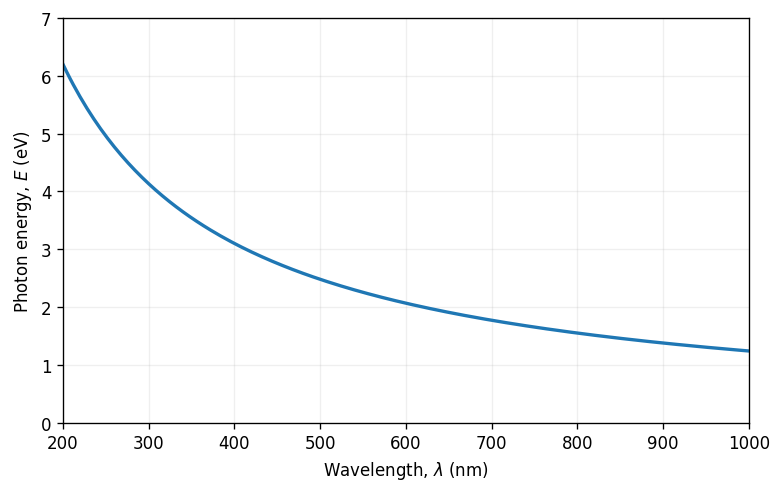

In [26]:
import numpy as np

import matplotlib.pyplot as plt

plot_wavelengths = np.arange(200.0, 1004.0, 4.0)  # Wavelengths from 200 through 1000 nm in 4 nm steps.
plot_energies = photon_energy_ev(plot_wavelengths)  # Photon energies, eV.
fig, ax = plt.subplots(figsize=(6.4, 4.0), layout="constrained")
ax.plot(plot_wavelengths, plot_energies, color="tab:blue", linewidth=2)
ax.set_xlabel(r"Wavelength, $\lambda$ (nm)")
ax.set_ylabel(r"Photon energy, $E$ (eV)")
ax.set_xlim(200, 1000)
ax.set_ylim(0, 7)
ax.grid(alpha=0.2)
plt.show()

The curve decreases, as expected from the inverse dependence. It is not a straight line: the same wavelength increase produces a larger energy change at short wavelengths than at long wavelengths. The axes identify the quantities and their units; explain the interpretation in the surrounding text rather than relying on a plot title.

To save a figure, place `fig.savefig("photon_energy.png", dpi=200, bbox_inches="tight")` before `plt.show()`. Download or copy that generated file out of a temporary Colab runtime if you need to keep it.

### Passing a function as an argument

Python functions can themselves be arguments. The following example passes `np.sin` and `np.cos` to one plotting function. Passing `np.sin` supplies the function; writing `np.sin(theta)` evaluates it first.

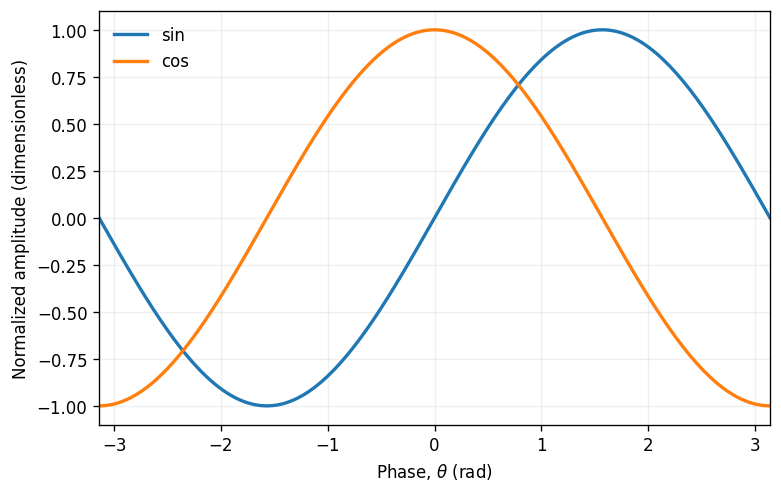

In [27]:
import numpy as np
import matplotlib.pyplot as plt

def plot_wave(axis, wave_function, phase, label):
    """Plot a dimensionless wave against phase in radians on the supplied axes."""
    axis.plot(phase, wave_function(phase), linewidth=2, label=label)

phase_step = np.pi / 100  # Phase increment, radians.
phase = np.arange(-100, 101, 1) * phase_step  # 201 phase samples from -pi to pi, radians.
fig_wave, ax_wave = plt.subplots(figsize=(6.4, 4.0), layout="constrained")
wave_functions = (np.sin, np.cos)
for wave_function in wave_functions:
    plot_wave(ax_wave, wave_function, phase, wave_function.__name__)
ax_wave.set_xlabel(r"Phase, $\theta$ (rad)")
ax_wave.set_ylabel("Normalized amplitude (dimensionless)")
ax_wave.set_xlim(-np.pi, np.pi)
ax_wave.set_ylim(-1.1, 1.1)
ax_wave.legend(loc="upper left", frameon=False)
ax_wave.grid(alpha=0.2)
plt.show()

Here, `wave_functions` is a tuple, and `__name__` supplies each function's name for the legend. Both curves have the same range and period but different phases. Passing the axes explicitly also avoids making the plotting function depend on a global variable named `ax`.

## Checking results and debugging

A cell can run without an error and still implement the wrong physics. Check dimensions, parameter ranges, signs, and a limiting case or known result. For example, the photon model predicts an exact energy ratio of one-half when the wavelength doubles.

In [28]:
import numpy as np

energy_500 = photon_energy_ev(500.0)  # Photon energy at 500 nm, eV.
energy_1000 = photon_energy_ev(1000.0)  # Photon energy at 1000 nm, eV.
energy_ratio = energy_1000 / energy_500
print(f"Energy ratio = {energy_ratio:.3f}")
print(np.isclose(energy_ratio, 0.5, rtol=1e-12, atol=0.0))

Energy ratio = 0.500
True


This check confirms that the implementation has the predicted scaling; it is not independent evidence that the model describes an experiment. A graph, dimensional check, or comparison with a separately obtained answer can provide additional information.

When a cell fails, read the last line of the error message and locate the referenced line of code. Print a few intermediate values, including their types or array shapes, before changing the whole calculation.

| Symptom | First thing to inspect |
| --- | --- |
| `NameError` | Spelling, capitalization, and whether the defining cell was executed |
| `SyntaxError` or `IndentationError` | Colons, parentheses, quotes, and indentation |
| `TypeError` | Whether the inputs are numbers, strings, lists, or arrays |
| `IndexError` | Array shape, zero-based indices, and slice limits |
| `ValueError` | Input domain, conversion, or incompatible array shapes |
| Division warning, `inf`, or `nan` | Zero denominators, invalid square roots, or other domain restrictions |
| Plausible but incorrect result | Units, parentheses, formula, and stale notebook variables |

```{tip}
**Work smart, not hard!** Open a relevant course notebook through the rocket ship and inspect its code before searching for an unrelated example. Adapt a short calculation that you understand, identify its inputs and assumptions, and predict how your changes should affect the output. Reusing syntax saves time; explaining and checking the physics remains your responsibility.
```

## Organizing your own calculation

Keep the computational dependencies easy to follow: required imports at the beginning of each cell, followed by its constants and inputs, calculations, and plots or checks. Make dependencies on earlier function definitions or data clear. Place explanatory text beside the code it describes. Functions can be defined in a logical order; alphabetical ordering is not required.

Use comments for physical meaning and units, simple loops where they help, and descriptive names. Keep function calls on one line. If a calculation becomes difficult to read, define a meaningful intermediate quantity rather than compressing everything into one expression. Python uses indentation to group statements; avoid unnecessary backslash line continuations.

A complete homework solution explains the method, interprets the results, and includes a reasonableness check in the conclusion. Follow the [homework template](https://saturnaxis.github.io/ModernPhysics/Preamble/HW_template.html) for sentence minimums, group-work procedures, and filenames. Submit both the `.ipynb` and its matching `.pdf`. Before printing, exit cell editing mode so text is fully rendered, and inspect the PDF for clipped figures or a source/preview split view.

For practice, change the wavelength interval in the photon plot, predict the energy range, and check the result. These are practice suggestions rather than extra submissions unless assigned.

## References

Use the official [Python tutorial](https://docs.python.org/3/tutorial/), [NumPy beginner guide](https://numpy.org/doc/stable/user/absolute_beginners.html), and [Matplotlib quick start](https://matplotlib.org/stable/users/explain/quick_start.html) for details. The Python explanation of [floating-point arithmetic](https://docs.python.org/3/tutorial/floatingpoint.html) and NumPy's [isclose documentation](https://numpy.org/doc/stable/reference/generated/numpy.isclose.html) explain why numerical comparisons need suitable tolerances.